# The confidence trap; lift near one: who is the worst partner?

**Week 4, Wednesday, chapter 4 of the concept block.** The topic, in the curriculum's words: *The confidence trap; lift near one*.
The examples are invented for this chapter, small enough to count by hand: every number below is counted from a table in `data/`, and the code only confirms the count.

**Who needs the answer.** The canteen manager, who is told that every dal rice order has chaas and is tempted to print chaas beside everything; a board full of chaas sells nothing that was not selling already.

**The questions on the way.** What is a base rate? What is dal rice to chaas worth? Does every item look bundled with chaas? Which count resists popularity?

In [1]:
def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)
    assert ok, name
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})
import pandas as pd
from collections import Counter
from itertools import combinations

lines = pd.read_csv("../data/C2_W04_D03_canteen_order_lines_STUDENT.csv")
listed = lines.groupby("order_id").item.apply(list)      # the items in the order the bill lists them
baskets = listed.apply(set)                               # one set of items per order
n = len(baskets)
print("A hostel canteen's twelve lunch orders, invented for the concept chapters:")
for order_id, held in listed.items():
    print(f"  {order_id}: {', '.join(held)}")


def has(item):
    """True for every order that holds the item."""
    return baskets.apply(lambda b: item in b)


check("twelve orders and 33 order lines", n == 12 and len(lines) == 33)

A hostel canteen's twelve lunch orders, invented for the concept chapters:
  T01: dal rice, papad, chaas
  T02: dal rice, papad, chaas
  T03: dal rice, papad, chaas
  T04: dal rice, sabzi, chaas
  T05: dal rice, chaas
  T06: dal rice, curd, chaas
  T07: roti, papad, pickle
  T08: papad, pickle
  T09: roti, sabzi, chaas
  T10: roti, sabzi, chaas
  T11: roti, sabzi, chaas
  T12: gulab jamun, curd
PASS twelve orders and 33 order lines


## Dal rice to chaas reads 1.00: what is their lift?

A **base rate** is how common an item is in all baskets anyway. Chaas is in 9 of the 12
orders, a base rate of 0.75, so it is in most of dal rice's orders whatever dal rice
does. Every dal rice order holds chaas.

**Predict before you run.** What is the lift of dal rice and chaas?

a) 1.00, the same as the confidence.
b) 1.33, the confidence over chaas's share.
c) 2.00, twice as strong as an ordinary pair.
d) 0.75, chaas's own share of the orders.

In [2]:
dal, chaas = has("dal rice"), has("chaas")
conf = (dal & chaas).sum() / dal.sum()
chance = n * dal.mean() * chaas.mean()
lift = (dal & chaas).sum() / chance
print(f"dal rice to chaas: confidence {conf:.2f}; chaas's base rate {chaas.mean():.2f}")
print(f"chance alone gives {chance:.1f} of dal rice's {dal.sum()} orders; {(dal & chaas).sum()} are seen; lift {lift:.2f}")
print(f"second route: {conf:.2f} / {chaas.mean():.2f} = {conf / chaas.mean():.2f}")
check("dal rice to chaas reads 1.00", conf == 1.0)
check("their lift is only 1.33", round(lift, 2) == 1.33)

dal rice to chaas: confidence 1.00; chaas's base rate 0.75
chance alone gives 4.5 of dal rice's 6 orders; 6 are seen; lift 1.33
second route: 1.00 / 0.75 = 1.33
PASS dal rice to chaas reads 1.00
PASS their lift is only 1.33


**What happened.** The answer is b. Chance alone already puts chaas in
4.5 of dal rice's 6 orders, so seeing it in all 6 is
1.33 times chance. **The trap, exactly:** 1.00 read as a
bundle. The decision it misleads is a combo board filled with chaas beside everything,
which changes nothing, since chaas was going into nine orders of twelve anyway. **The
check** is chaas's own share; **the fix** is to read lift. The picture runs the same test
on every item in four or more orders.

          confidence toward chaas  lift with chaas
dal rice                     1.00             1.33
papad                        0.60             0.80
roti                         0.75             1.00
sabzi                        1.00             1.33


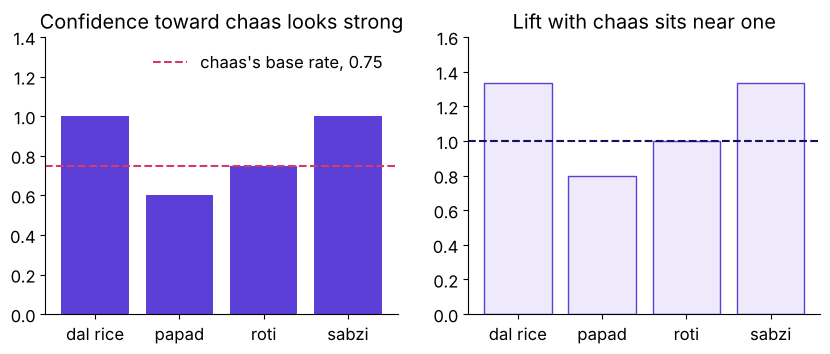

PASS confidence toward chaas runs 0.60 to 1.00
PASS lift with chaas runs 0.80 to 1.33


In [3]:
common = [x for x in ["dal rice", "papad", "roti", "sabzi"] if has(x).sum() >= 4]
conf_to = pd.Series({x: (has(x) & chaas).sum() / has(x).sum() for x in common})
lift_with = conf_to / chaas.mean()
print(pd.DataFrame({"confidence toward chaas": conf_to, "lift with chaas": lift_with}).round(2).to_string())
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
a1.bar(common, conf_to, color="#5B3FD6")
a1.axhline(chaas.mean(), color="#D63A6A", ls="--", label="chaas's base rate, 0.75")
a1.set_ylim(0, 1.4)
a1.legend(frameon=False, loc="upper right")
a1.set_title("Confidence toward chaas looks strong")
a2.bar(common, lift_with, color="#EEEAFB", edgecolor="#5B3FD6")
a2.axhline(1, color="#1A0F5C", ls="--")
a2.set_ylim(0, 1.6)
a2.set_title("Lift with chaas sits near one")
plt.show()
check("confidence toward chaas runs 0.60 to 1.00", (conf_to.min(), conf_to.max()) == (0.6, 1.0))
check("lift with chaas runs 0.80 to 1.33", (round(lift_with.min(), 2), round(lift_with.max(), 2)) == (0.8, 1.33))

## What does popularity do to confidence in general?

An invented sweep makes the rule visible. A partner that ignores a popular item holds it
at the item's own share, so its confidence toward the popular item equals that share: as
the share climbs from 20 to 90 percent, the confidence climbs with it, and lift stays at
one the whole way.

 share  confidence  lift
   0.2         0.2   1.0
   0.5         0.5   1.0
   0.9         0.9   1.0


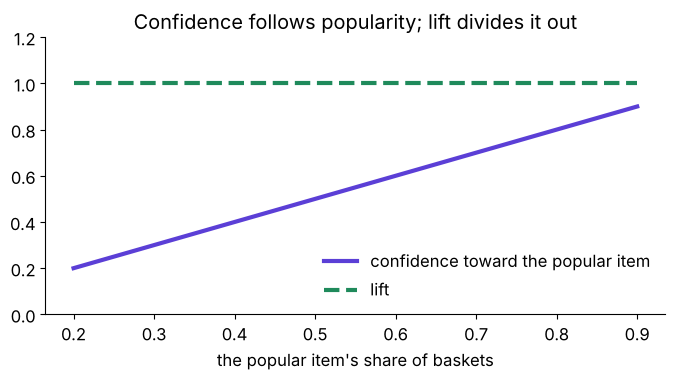

PASS lift stays at one across the sweep


In [4]:
rows = []
for share in [x / 100 for x in range(20, 91, 5)]:
    partner_baskets = 20                        # an invented partner in 20 baskets
    holding_popular = partner_baskets * share   # it ignores the popular item
    confidence = holding_popular / partner_baskets
    rows.append((share, confidence, confidence / share))
sweep = pd.DataFrame(rows, columns=["share", "confidence", "lift"])
print(sweep[sweep.share.isin([0.2, 0.5, 0.9])].round(2).to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(sweep.share, sweep.confidence, color="#5B3FD6", lw=3, label="confidence toward the popular item")
ax.plot(sweep.share, sweep.lift, color="#1F8A5B", lw=3, ls="--", label="lift")
ax.set_xlabel("the popular item's share of baskets")
ax.set_ylim(0, 1.2)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Confidence follows popularity; lift divides it out")
plt.show()
check("lift stays at one across the sweep", (sweep.lift - 1).abs().max() < 1e-9)

## How close to chance does each chaas pair sit?

The rule, named last: for a partner that ignores it, confidence toward an item equals
that item's share, so the most popular item wins every confidence ranking while lift
stays at one. Lift is the count popularity cannot fool. The picture shows the same thing
on the canteen's four chaas pairs as counts: the seen orders beside the orders chance
alone gives.

dal rice + chaas: seen 6, chance 4.50
papad + chaas: seen 3, chance 3.75
roti + chaas: seen 3, chance 3.00
sabzi + chaas: seen 4, chance 3.00


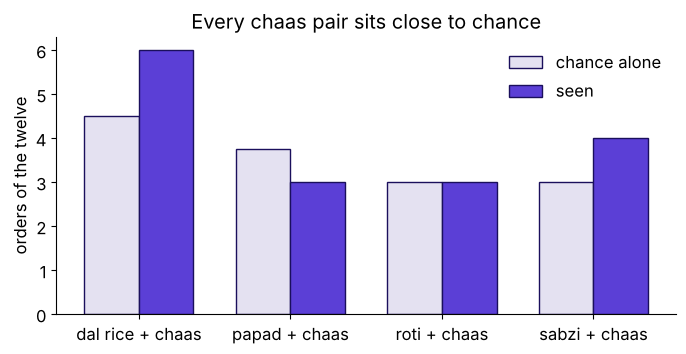

PASS no chaas pair sits more than 1.5 orders from chance


In [5]:
rows = []
for x in common:
    k = (has(x) & chaas).sum()
    e = n * has(x).mean() * chaas.mean()
    rows.append((f"{x} + chaas", k, e))
    print(f"{x} + chaas: seen {k}, chance {e:.2f}")
fig, ax = plt.subplots(figsize=(8, 3.6))
x = range(len(rows))
ax.bar([i - 0.18 for i in x], [e for _, _, e in rows], 0.36, color="#E4E1F1", edgecolor="#1A0F5C", label="chance alone")
ax.bar([i + 0.18 for i in x], [k for _, k, _ in rows], 0.36, color="#5B3FD6", edgecolor="#1A0F5C", label="seen")
ax.set_xticks(list(x), [name for name, _, _ in rows])
ax.set_ylabel("orders of the twelve")
ax.legend(frameon=False)
ax.set_title("Every chaas pair sits close to chance")
plt.show()
check("no chaas pair sits more than 1.5 orders from chance", all(abs(k - e) <= 1.5 for _, k, e in rows))

### Your turn: should a shop bundle a partner with its most popular item?

An item is in 60 percent of a shop's bills, and a partner reads confidence 0.66 toward
it. In the empty cell below, compute the pair's lift and store it as `partner_lift`, then
write in a comment whether you would bundle the two. Run the check under it.

In [6]:
reference = 0.66 / 0.60
mine = globals().get("partner_lift")
print(f"reference: lift {reference:.2f}" + ("" if mine is None else f"; yours: {mine:.2f}"))
check("a confidence of 0.66 toward an item in 60 percent of bills is lift 1.10", round(reference, 2) == 1.1)
if mine is not None:
    check("your lift matches the reference", abs(mine - reference) < 1e-9)

reference: lift 1.10
PASS a confidence of 0.66 toward an item in 60 percent of bills is lift 1.10


## What should you keep from chapter 4?

- A base rate is how common an item is in all baskets anyway: chaas
  0.75.
- An item in most baskets earns high confidence toward everything, near its own share:
  0.60 to 1.00 toward chaas.
- Lift divides the base rate out, so only lift can rank the partners of a popular item:
  0.80 to 1.33 with chaas.
- The item in every basket is the worst bundle partner, because it was going into the
  basket anyway.

**In the interview.** A weak answer says "confidence, since dal rice to chaas is 1.00". A
hire-grade answer says "lift, since chaas is in 0.75 of orders anyway, so 1.00 is only
1.33 times chance". Chapter 8 meets the same trap on milk, in 71 percent of Instamart's
carts.